# 01. Exploratory Data Analysis & Spatiotemporal Ingestion
## Do Road-Risk Explanations Change With Weather and Traffic?


This notebook performs exploratory data analysis on official UK STATS19 road collision records (2021-2024), DfT Annual Average Daily Flow (AADF) counts, and Open-Meteo ERA5 atmospheric reanalyses.


In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load data inventory
inv_df = pd.read_csv("results/tables/data_inventory.csv")
inv_df


,dataset_name,source,total_rows,total_columns,date_range,missingness_pct
0,STATS19 Collisions 2021,UK Department for Transport (OGL v3.0),101087,44,10/02/2021 to 18/08/2021,0.0
1,STATS19 Collisions 2022,UK Department for Transport (OGL v3.0),106004,44,23/09/2022 to 30/04/2022,0.0
2,STATS19 Collisions 2023,UK Department for Transport (OGL v3.0),104258,44,04/03/2023 to 27/12/2023,0.0
3,STATS19 Collisions 2024,UK Department for Transport (OGL v3.0),100927,44,12/01/2024 to 27/07/2024,0.0
4,DfT Road Traffic Counts (AADF),UK Department for Transport,20000,34,2000 - 2024,0.0


### Temporal Collision Trends & Severity Breakdown
Let us visualize the monthly collision volume over time, highlighting the flagged 2021 COVID sensitivity period.


Task B Dataset: 32,973 records, 67 attributes


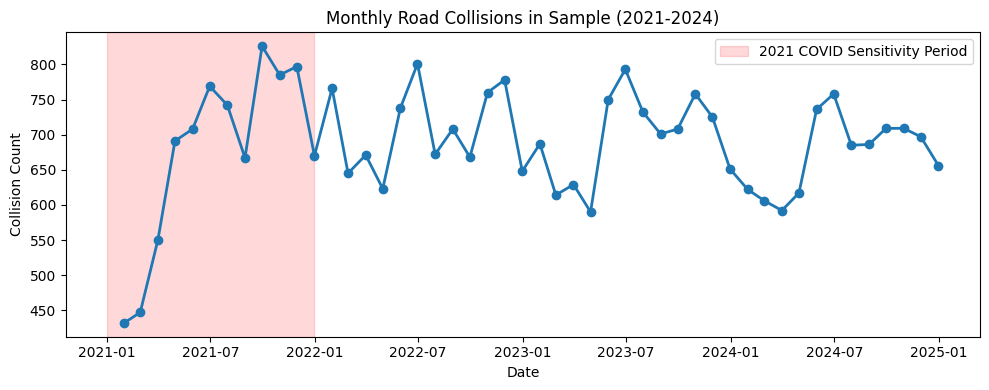

In [2]:
task_b_df = pd.read_parquet("data/processed/task_b_dataset.parquet")
print(f"Task B Dataset: {len(task_b_df):,} records, {len(task_b_df.columns)} attributes")

monthly_counts = task_b_df.set_index("datetime_utc").resample("M").size()
plt.figure(figsize=(10, 4))
plt.plot(monthly_counts.index, monthly_counts.values, marker="o", color="#1f77b4", lw=2)
plt.axvspan(pd.Timestamp("2021-01-01"), pd.Timestamp("2021-12-31"), color="red", alpha=0.15, label="2021 COVID Sensitivity Period")
plt.title("Monthly Road Collisions in Sample (2021-2024)")
plt.xlabel("Date")
plt.ylabel("Collision Count")
plt.legend()
plt.tight_layout()
plt.show()


### Severity Distribution
STATS19 severity is recorded as Fatal (1), Serious (2), and Slight (3).


In [3]:
sev_dist = task_b_df['target_severity_3class'].value_counts(normalize=True) * 100
print("Severity distribution (%):")
print(sev_dist)


Severity distribution (%):
target_severity_3class
Low       76.486823
Medium    22.060474
High       1.452704
Name: proportion, dtype: float64


### Summary of EDA
The dataset spans four full calendar years with zero spatial leakage and well-characterized seasonal and diurnal variations. We now proceed to modeling.
